# Task 1 — Klasifikasi Multimodal Cacat Produk: Fusi Gambar dan Sensor

**Ruang lingkup.** Bagian ini menjawab butir (b) dan (c) pada soal Task 1, serta tahap awal butir (f):
- membandingkan dua strategi fusi, yaitu fusi tingkat fitur (A) dan fusi tingkat keputusan (B);
- mengukur kontribusi tiap modalitas (gambar saja, sensor saja, dan gabungan), termasuk per kelas;
- menguji ketahanan model ketika data sensor tidak terekam, dengan teknik *modality dropout*.

**Hasil awal (baseline satu modalitas).** Pada satu seed dan 10 epoch dengan bobot kelas 1/frekuensi, model gambar saja memperoleh macro-F1 0,573 (lini A 0,630; lini B 0,421), sedangkan model sensor saja memperoleh 0,413 (lini A 0,425; lini B 0,379). Kelas `las_dingin` dan `gelembung` lebih mudah dikenali dari sensor, sedangkan `kontaminasi`, `noda`, dan `gores` lebih mudah dikenali dari gambar. Model gambar menurun tajam pada lini B, yang citranya lebih gelap (rata-rata intensitas 111,7 dibanding 139,8 pada lini A).

**Alur.** 0 Persiapan → 1 Model satu modalitas → 2 Fusi A → 3 Fusi B → 4 Sensor tidak terekam → 5 Perbandingan per kelas → 6 Kesimpulan → 7 Penyimpanan hasil.

## 0. Persiapan lingkungan dan data

Eksperimen dijalankan di Google Colab dengan GPU NVIDIA T4. Bagian ini memeriksa GPU, mencatat versi library, mengunduh dataset dari folder yang disediakan, dan menyiapkan repositori kerja. Notebook ini berdiri sendiri dan dapat dijalankan dari awal.

In [1]:
# Cek GPU dan catat versi library (untuk reproduksibilitas, diminta soal)
import torch, numpy, pandas, sklearn, sys
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", numpy.__version__,
      "| pandas", pandas.__version__, "| sklearn", sklearn.__version__)
print("GPU tersedia:", torch.cuda.is_available())
assert torch.cuda.is_available(), "Aktifkan T4 GPU dulu: Runtime -> Change runtime type"

Python 3.13.16 | torch 2.14.1+cu130 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1
GPU tersedia: True


In [2]:
# Data: unduh dari folder dosen (tanpa mount Drive)
import os
if not os.path.exists('/content/data/klasifikasi_train.npz'):
    !gdown 10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb -O /content/data_uts_dl.zip
    !mkdir -p /content/data && unzip -q /content/data_uts_dl.zip -d /content/data
!ls /content/data

Downloading...
From (original): https://drive.google.com/uc?id=10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb
From (redirected): https://drive.google.com/uc?id=10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb&confirm=t&uuid=857ae61c-6118-48f1-a7c6-d62fcd4f69bc
To: /content/data_uts_dl.zip
100% 396M/396M [00:07<00:00, 55.1MB/s]
clustering_meta.csv  klasifikasi_test_meta.csv	 klasifikasi_train.npz
clustering.npz	     klasifikasi_test.npz	 rul_test.csv.gz
kamus_data.md	     klasifikasi_train_meta.csv  rul_train.csv.gz


In [3]:
# Repo: clone fork, ambil main terbaru dari repo kelompok, buat branch kerja
from google.colab import userdata
import os
token = userdata.get('GH_TOKEN')
if not os.path.exists('/content/UTSDEEPLEARNING'):
    !git clone https://{token}@github.com/rafiptrnto/UTSDEEPLEARNING.git /content/UTSDEEPLEARNING
%cd /content/UTSDEEPLEARNING
!git config user.name "rafiptrnto"
!git config user.email "rafiputranto665@gmail.com"
!git remote add upstream https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING.git 2>/dev/null || true
!git pull upstream main
!git checkout -B task1-fusi
!mkdir -p kode/task1_klasifikasi

Cloning into '/content/UTSDEEPLEARNING'...
remote: Enumerating objects: 61, done.
remote: Counting objects: 100% (61/61), done.
remote: Compressing objects: 100% (45/45), done.
remote: Total 61 (delta 17), reused 38 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (61/61), 772.22 KiB | 2.37 MiB/s, done.
Resolving deltas: 100% (17/17), done.
/content/UTSDEEPLEARNING
remote: Enumerating objects: 1, done.
remote: Counting objects: 100% (1/1), done.
remote: Total 1 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (1/1), 934 bytes | 934.00 KiB/s, done.
From https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING
 * branch            main       -> FETCH_HEAD
 * [new branch]      main       -> upstream/main
Updating a4c56ff..8f6eb59
Fast-forward
 kode/task1_klasifikasi/fusion.py             |  75 +++++++++++++++++
 kode/task1_klasifikasi/hasil/fusi_seed0.json | 119 +++++++++++++++++++++++++++
 2 files changed, 194 insertions(+)
 create mode 100644 kode/task1_k

### Kode pendukung

Kode inti disimpan sebagai berkas Python di `kode/task1_klasifikasi/` agar tercatat di repositori dan dapat dijalankan ulang oleh penguji.

| Berkas | Isi |
|---|---|
| `data.py` | pemuatan data, normalisasi sensor, pembagian data latih dan validasi |
| `models.py` | encoder gambar (CNN 2D) dan encoder sensor (CNN 1D) |
| `train_utils.py` | pelatihan model satu modalitas, metrik macro-F1, laporan per lini |
| `fusion.py` | model fusi, modality dropout, pelatihan dua input, dan fusi keputusan |

In [4]:
%%writefile /content/UTSDEEPLEARNING/kode/task1_klasifikasi/data.py
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split

KELAS = ['normal', 'gores', 'noda', 'retak', 'gelembung', 'las_dingin', 'kontaminasi']
K2I = {k: i for i, k in enumerate(KELAS)}

def load(split, data_dir="/content/data"):
    z = np.load(f"{data_dir}/klasifikasi_{split}.npz")
    meta = pd.read_csv(f"{data_dir}/klasifikasi_{split}_meta.csv")
    img = z['gambar'].astype(np.float32) / 255.0      # (N, 64, 64)
    sen = z['sensor'].astype(np.float32)               # (N, 3, 128), NaN = tidak terekam
    y = meta['kelas'].map(K2I).values if 'kelas' in meta.columns else None
    return img, sen, meta, y

def sensor_stats(sen):
    return (np.nanmean(sen, axis=(0, 2), keepdims=True),
            np.nanstd(sen, axis=(0, 2), keepdims=True))

def prep_sensor(sen, mean, std):
    mask = (~np.isnan(sen)).astype(np.float32)          # 1 = ada data
    x = np.nan_to_num((sen - mean) / std, nan=0.0)
    return np.concatenate([x, mask], axis=1)            # (N, 6, 128)

def make_split(meta, y, seed=0, frac=0.2):
    strat = meta['kelas'].astype(str) + '_' + meta['lini']
    tr, va = train_test_split(np.arange(len(meta)), test_size=frac,
                              stratify=strat, random_state=seed)
    return tr, va

Overwriting /content/UTSDEEPLEARNING/kode/task1_klasifikasi/data.py


In [5]:
%%writefile /content/UTSDEEPLEARNING/kode/task1_klasifikasi/models.py
import torch.nn as nn

def conv_block(i, o):
    return nn.Sequential(
        nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
        nn.MaxPool2d(2))

class ImageCNN(nn.Module):
    def __init__(self, n_class=7):
        super().__init__()
        self.body = nn.Sequential(conv_block(1, 32), conv_block(32, 64),
                                  conv_block(64, 128), conv_block(128, 128))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Linear(128, n_class)
    def features(self, x):
        return self.pool(self.body(x)).flatten(1)
    def forward(self, x):
        return self.head(self.features(x))

class SensorCNN(nn.Module):
    def __init__(self, in_ch=6, n_class=7):
        super().__init__()
        def blk(i, o):
            return nn.Sequential(nn.Conv1d(i, o, 5, padding=2), nn.BatchNorm1d(o),
                                 nn.ReLU(inplace=True), nn.MaxPool1d(2))
        self.body = nn.Sequential(blk(in_ch, 32), blk(32, 64), blk(64, 128), blk(128, 128))
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.head = nn.Linear(128, n_class)
    def features(self, x):
        return self.pool(self.body(x)).flatten(1)
    def forward(self, x):
        return self.head(self.features(x))

Overwriting /content/UTSDEEPLEARNING/kode/task1_klasifikasi/models.py


In [6]:
%%writefile /content/UTSDEEPLEARNING/kode/task1_klasifikasi/train_utils.py
import numpy as np, torch, torch.nn as nn
from sklearn.metrics import f1_score, classification_report
from torch.utils.data import TensorDataset, DataLoader
from data import KELAS

def get_loader(X, y, idx, bs=256, shuffle=False):
    ds = TensorDataset(torch.from_numpy(X[idx]), torch.from_numpy(y[idx]).long())
    return DataLoader(ds, batch_size=bs, shuffle=shuffle)

@torch.no_grad()
def predict(model, loader, device):
    model.eval(); out = []
    for xb, _ in loader:
        out.append(model(xb.to(device)).argmax(1).cpu())
    return torch.cat(out).numpy()

def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average='macro')

def fit(model, X, y, tr_idx, va_idx, epochs=10, lr=1e-3, bs=256,
        class_weight=None, device='cuda', seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    model.to(device)
    w = None if class_weight is None else torch.tensor(class_weight, dtype=torch.float32, device=device)
    loss_fn = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    steps = epochs * int(np.ceil(len(tr_idx) / bs))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps)
    tl, vl = get_loader(X, y, tr_idx, bs, True), get_loader(X, y, va_idx, bs)
    hist = []
    for ep in range(epochs):
        model.train(); tot = 0.0
        for xb, yb in tl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward(); opt.step(); sched.step()
            tot += loss.item() * len(xb)
        f1 = macro_f1(y[va_idx], predict(model, vl, device))
        hist.append((tot / len(tr_idx), f1))
        print(f"ep {ep+1}: loss {hist[-1][0]:.4f} | val macro-F1 {f1:.4f}")
    return hist

def overfit_one_batch(model, X, y, idx, n=64, steps=200, lr=1e-3, device='cuda'):
    model.to(device).train()
    xb = torch.from_numpy(X[idx[:n]]).to(device)
    yb = torch.from_numpy(y[idx[:n]]).long().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for s in range(steps):
        opt.zero_grad()
        loss = nn.functional.cross_entropy(model(xb), yb)
        loss.backward(); opt.step()
        if s % 50 == 0 or s == steps - 1:
            print(s, round(loss.item(), 4))

def report(y_true, y_pred, lini):
    print("macro-F1 total:", round(macro_f1(y_true, y_pred), 4))
    for l in ['A', 'B']:
        m = (lini == l)
        print(f"lini {l}: macro-F1 {macro_f1(y_true[m], y_pred[m]):.4f}")
    print(classification_report(y_true, y_pred, target_names=KELAS, digits=3))

Overwriting /content/UTSDEEPLEARNING/kode/task1_klasifikasi/train_utils.py


In [7]:
%%writefile /content/UTSDEEPLEARNING/kode/task1_klasifikasi/fusion.py
import numpy as np, torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score
from models import ImageCNN, SensorCNN
from train_utils import get_loader

def get_loader2(Xi, Xs, y, idx, bs=256, shuffle=False):
    """Loader dengan dua input: gambar, sensor, dan label."""
    ds = TensorDataset(torch.from_numpy(Xi[idx]), torch.from_numpy(Xs[idx]),
                       torch.from_numpy(y[idx]).long())
    return DataLoader(ds, batch_size=bs, shuffle=shuffle)

class FusionNet(nn.Module):
    """Fusi tingkat fitur: vektor fitur gambar (128) + vektor fitur sensor (128) -> 256 -> kelas."""
    def __init__(self, n_class=7):
        super().__init__()
        self.img = ImageCNN(n_class)
        self.sen = SensorCNN(6, n_class)
        self.head = nn.Sequential(nn.Linear(256, 128), nn.ReLU(inplace=True),
                                  nn.Dropout(0.3), nn.Linear(128, n_class))
    def forward(self, xi, xs):
        return self.head(torch.cat([self.img.features(xi), self.sen.features(xs)], dim=1))

def drop_sensor(xs, p):
    """Modality dropout: dengan peluang p, seluruh sensor sebuah sampel dikosongkan
    (sinyal = 0 dan mask = 0), identik dengan representasi sensor yang tidak terekam."""
    if p <= 0:
        return xs
    keep = (torch.rand(xs.shape[0], 1, 1, device=xs.device) >= p).float()
    return xs * keep

@torch.no_grad()
def predict_fusion(model, loader, device, sensor_off=False, proba=False):
    model.eval(); out = []
    for xi, xs, _ in loader:
        xi, xs = xi.to(device), xs.to(device)
        if sensor_off:
            xs = torch.zeros_like(xs)
        logits = model(xi, xs)
        out.append(logits.softmax(1).cpu() if proba else logits.argmax(1).cpu())
    return torch.cat(out).numpy()

def fit_fusion(model, Xi, Xs, y, tr_idx, va_idx, epochs=15, lr=1e-3, bs=256,
               class_weight=None, p_drop=0.0, device='cuda', seed=0):
    torch.manual_seed(seed); np.random.seed(seed)
    model.to(device)
    w = None if class_weight is None else torch.tensor(class_weight, dtype=torch.float32, device=device)
    loss_fn = nn.CrossEntropyLoss(weight=w)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    steps = epochs * int(np.ceil(len(tr_idx) / bs))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps)
    tl = get_loader2(Xi, Xs, y, tr_idx, bs, True)
    vl = get_loader2(Xi, Xs, y, va_idx, bs)
    hist = []
    for ep in range(epochs):
        model.train(); tot = 0.0
        for xi, xs, yb in tl:
            xi, xs, yb = xi.to(device), xs.to(device), yb.to(device)
            xs = drop_sensor(xs, p_drop)
            opt.zero_grad()
            loss = loss_fn(model(xi, xs), yb)
            loss.backward(); opt.step(); sched.step()
            tot += loss.item() * len(yb)
        f1 = f1_score(y[va_idx], predict_fusion(model, vl, device), average='macro')
        hist.append((tot / len(tr_idx), f1))
        print(f"ep {ep+1}: loss {hist[-1][0]:.4f} | val macro-F1 {f1:.4f}")
    return hist

@torch.no_grad()
def proba_single(model, X, y, idx, device, bs=512):
    """Probabilitas kelas dari model satu modalitas (untuk fusi keputusan)."""
    model.eval(); out = []
    for xb, _ in get_loader(X, y, idx, bs):
        out.append(model(xb.to(device)).softmax(1).cpu())
    return torch.cat(out).numpy()

Overwriting /content/UTSDEEPLEARNING/kode/task1_klasifikasi/fusion.py


### Pemuatan data dan keputusan desain

- **Pembagian data.** Data latih dibagi 80% untuk pelatihan dan 20% untuk validasi, dengan stratifikasi berdasarkan kombinasi kelas dan lini produksi. Proporsi lini A dan B pada data validasi sama dengan data latih (sekitar 75% dan 25%).
- **Normalisasi sensor.** Rata-rata dan simpangan baku dihitung hanya dari data latih, sehingga tidak ada informasi dari data validasi yang masuk ke proses pelatihan.
- **Sensor tidak terekam.** Nilai NaN diganti 0 dan ditambahkan tiga kanal *mask* (1 = data ada, 0 = hilang), sehingga model dapat membedakan nilai nol sungguhan dari data yang hilang.
- **Bobot kelas.** Kelas `normal` mencakup hampir 50% data latih. Pada baseline, bobot 1/frekuensi menghasilkan recall `normal` yang rendah (0,376) dengan precision yang tinggi (0,734), yang menunjukkan penekanan berlebih terhadap kelas mayoritas. Kami menguji bobot yang lebih lunak, yaitu akar dari 1/frekuensi, dan menerapkannya pada semua model agar perbandingan tetap adil.
- **Seed.** Eksperimen ini memakai seed 0. Model final akan dievaluasi dengan tiga seed (butir g).

In [8]:
import sys
sys.path.append('/content/UTSDEEPLEARNING/kode/task1_klasifikasi')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import f1_score
from data import *
from models import *
from train_utils import *
from fusion import *

SEED = 0
EPOCHS = 15          # jumlah epoch pelatihan
device = 'cuda'

img, sen, meta, y = load('train')
tr_idx, va_idx = make_split(meta, y, seed=SEED)

m, s = sensor_stats(sen[tr_idx])          # statistik HANYA dari data latih
X_sen = prep_sensor(sen, m, s)            # (N, 6, 128)
X_img = img[:, None]                      # (N, 1, 64, 64)

yv = y[va_idx]
lini_va = meta['lini'].values[va_idx]
cw = (len(y) / (7 * np.bincount(y))) ** 0.5    # bobot kelas (akar dari 1/frekuensi)

print("gambar:", X_img.shape, "| sensor:", X_sen.shape, "| latih/valid:", len(tr_idx), len(va_idx))
print("bobot kelas:", dict(zip(KELAS, cw.round(2))))

gambar: (48000, 1, 64, 64) | sensor: (48000, 6, 128) | latih/valid: 38400 9600
bobot kelas: {'normal': np.float64(0.54), 'gores': np.float64(1.1), 'noda': np.float64(1.2), 'retak': np.float64(1.38), 'gelembung': np.float64(1.41), 'las_dingin': np.float64(1.26), 'kontaminasi': np.float64(1.71)}


In [9]:
# Pencatat hasil: semua model dibandingkan pada data validasi yang sama
HASIL = {}

def ringkas(nama, y_true, y_pred, lini):
    per = f1_score(y_true, y_pred, average=None, labels=list(range(7)))
    HASIL[nama] = dict(
        total=float(f1_score(y_true, y_pred, average='macro')),
        A=float(f1_score(y_true[lini == 'A'], y_pred[lini == 'A'], average='macro')),
        B=float(f1_score(y_true[lini == 'B'], y_pred[lini == 'B'], average='macro')),
        per_kelas={k: float(v) for k, v in zip(KELAS, per)})
    h = HASIL[nama]
    print(f"{nama}: macro-F1 {h['total']:.4f} | lini A {h['A']:.4f} | lini B {h['B']:.4f}")

## 1. Model satu modalitas (pembanding)

Model gambar dan model sensor dilatih ulang dengan jumlah epoch dan bobot kelas yang sama dengan model fusi. Hasilnya menjadi dasar analisis butir (c), yaitu kelas yang bergantung pada modalitas gambar dan kelas yang bergantung pada modalitas sensor.

In [10]:
# Gambar saja
m_img = ImageCNN()
fit(m_img, X_img, y, tr_idx, va_idx, epochs=EPOCHS, class_weight=cw, device=device, seed=SEED)
pv_img = predict(m_img, get_loader(X_img, y, va_idx), device)
N_IMG = 'Gambar saja'
ringkas(N_IMG, yv, pv_img, lini_va)

ep 1: loss 1.7783 | val macro-F1 0.2301
ep 2: loss 1.4929 | val macro-F1 0.3469
ep 3: loss 1.3391 | val macro-F1 0.3596
ep 4: loss 1.1959 | val macro-F1 0.4599
ep 5: loss 1.0695 | val macro-F1 0.5118
ep 6: loss 0.9664 | val macro-F1 0.5143
ep 7: loss 0.9100 | val macro-F1 0.4381
ep 8: loss 0.8360 | val macro-F1 0.5682
ep 9: loss 0.7694 | val macro-F1 0.5917
ep 10: loss 0.6868 | val macro-F1 0.5763
ep 11: loss 0.5845 | val macro-F1 0.5939
ep 12: loss 0.4730 | val macro-F1 0.5980
ep 13: loss 0.3783 | val macro-F1 0.6046
ep 14: loss 0.3177 | val macro-F1 0.6150
ep 15: loss 0.2942 | val macro-F1 0.6131
Gambar saja: macro-F1 0.6131 | lini A 0.6589 | lini B 0.4740


In [11]:
# Sensor saja
m_sen = SensorCNN()
fit(m_sen, X_sen, y, tr_idx, va_idx, epochs=EPOCHS, class_weight=cw, device=device, seed=SEED)
pv_sen = predict(m_sen, get_loader(X_sen, y, va_idx), device)
N_SEN = 'Sensor saja'
ringkas(N_SEN, yv, pv_sen, lini_va)

ep 1: loss 1.7392 | val macro-F1 0.2998
ep 2: loss 1.4156 | val macro-F1 0.3998
ep 3: loss 1.2438 | val macro-F1 0.4351
ep 4: loss 1.2007 | val macro-F1 0.4346
ep 5: loss 1.1837 | val macro-F1 0.4389
ep 6: loss 1.1701 | val macro-F1 0.4296
ep 7: loss 1.1583 | val macro-F1 0.4319
ep 8: loss 1.1467 | val macro-F1 0.4242
ep 9: loss 1.1327 | val macro-F1 0.4365
ep 10: loss 1.1141 | val macro-F1 0.4377
ep 11: loss 1.0906 | val macro-F1 0.4430
ep 12: loss 1.0616 | val macro-F1 0.4365
ep 13: loss 1.0290 | val macro-F1 0.4522
ep 14: loss 1.0040 | val macro-F1 0.4505
ep 15: loss 0.9913 | val macro-F1 0.4482
Sensor saja: macro-F1 0.4482 | lini A 0.4599 | lini B 0.4129


## 2. Strategi A: fusi tingkat fitur

Gambar diproses oleh encoder CNN 2D dan sensor oleh encoder CNN 1D. Masing-masing menghasilkan vektor fitur berdimensi 128. Kedua vektor digabung (*concatenate*, menjadi 256 dimensi) dan diteruskan ke lapisan klasifikasi. Seluruh jaringan dilatih bersama, sehingga kedua encoder belajar fitur yang saling melengkapi.

Keunggulan strategi ini adalah kemampuannya memanfaatkan interaksi antar modalitas, misalnya gambar yang mencurigakan bersamaan dengan arus yang rendah. Kelemahannya, model yang tidak pernah dilatih tanpa sensor dapat menghasilkan prediksi yang buruk ketika masukan sensor kosong.

Dua varian dibandingkan:
- **A0:** tanpa *modality dropout*.
- **A1:** dengan *modality dropout* berpeluang 0,3. Pada setiap iterasi pelatihan, 30% sampel dikosongkan sensornya (sinyal 0 dan mask 0, representasi yang sama dengan sensor yang tidak terekam), sehingga model dipaksa belajar mengandalkan gambar ketika sensor tidak ada. Teknik ini menjadi jawaban awal untuk butir (f).

In [12]:
# A0: tanpa modality dropout
fusiA0 = FusionNet()
fit_fusion(fusiA0, X_img, X_sen, y, tr_idx, va_idx, epochs=EPOCHS, class_weight=cw,
           p_drop=0.0, device=device, seed=SEED)
vl2 = get_loader2(X_img, X_sen, y, va_idx)
N_A0 = 'Fusi A0 (tanpa dropout)'
ringkas(N_A0, yv, predict_fusion(fusiA0, vl2, device), lini_va)
ringkas(N_A0 + ' | sensor hilang', yv, predict_fusion(fusiA0, vl2, device, sensor_off=True), lini_va)

ep 1: loss 1.7393 | val macro-F1 0.2965
ep 2: loss 1.0970 | val macro-F1 0.6945
ep 3: loss 0.8123 | val macro-F1 0.7354
ep 4: loss 0.7107 | val macro-F1 0.7255
ep 5: loss 0.6328 | val macro-F1 0.7617
ep 6: loss 0.5625 | val macro-F1 0.7239
ep 7: loss 0.5116 | val macro-F1 0.7301
ep 8: loss 0.4696 | val macro-F1 0.7656
ep 9: loss 0.4364 | val macro-F1 0.8167
ep 10: loss 0.3801 | val macro-F1 0.8177
ep 11: loss 0.3228 | val macro-F1 0.8160
ep 12: loss 0.2684 | val macro-F1 0.8226
ep 13: loss 0.2161 | val macro-F1 0.8212
ep 14: loss 0.1788 | val macro-F1 0.8228
ep 15: loss 0.1602 | val macro-F1 0.8214
Fusi A0 (tanpa dropout): macro-F1 0.8214 | lini A 0.8621 | lini B 0.6997
Fusi A0 (tanpa dropout) | sensor hilang: macro-F1 0.5644 | lini A 0.6130 | lini B 0.4243


In [13]:
# A1: dengan modality dropout 0,3
fusiA1 = FusionNet()
fit_fusion(fusiA1, X_img, X_sen, y, tr_idx, va_idx, epochs=EPOCHS, class_weight=cw,
           p_drop=0.3, device=device, seed=SEED)
N_A1 = 'Fusi A1 (dropout 0,3)'
ringkas(N_A1, yv, predict_fusion(fusiA1, vl2, device), lini_va)
ringkas(N_A1 + ' | sensor hilang', yv, predict_fusion(fusiA1, vl2, device, sensor_off=True), lini_va)

ep 1: loss 1.7525 | val macro-F1 0.4126
ep 2: loss 1.2540 | val macro-F1 0.6637
ep 3: loss 0.9958 | val macro-F1 0.6624
ep 4: loss 0.8852 | val macro-F1 0.7158
ep 5: loss 0.7951 | val macro-F1 0.7709
ep 6: loss 0.7219 | val macro-F1 0.6957
ep 7: loss 0.6706 | val macro-F1 0.7051
ep 8: loss 0.6163 | val macro-F1 0.8051
ep 9: loss 0.5783 | val macro-F1 0.8146
ep 10: loss 0.5245 | val macro-F1 0.8258
ep 11: loss 0.4719 | val macro-F1 0.8370
ep 12: loss 0.4191 | val macro-F1 0.8405
ep 13: loss 0.3655 | val macro-F1 0.8316
ep 14: loss 0.3257 | val macro-F1 0.8350
ep 15: loss 0.3042 | val macro-F1 0.8325
Fusi A1 (dropout 0,3): macro-F1 0.8325 | lini A 0.8682 | lini B 0.7259
Fusi A1 (dropout 0,3) | sensor hilang: macro-F1 0.6078 | lini A 0.6530 | lini B 0.4697


## 3. Strategi B: fusi tingkat keputusan

Model gambar dan model sensor dari bagian 1 dilatih secara terpisah. Keduanya menghasilkan probabilitas untuk tujuh kelas, yang digabung dengan rata-rata berbobot:

`p_akhir = w · p_gambar + (1 − w) · p_sensor`

Bobot `w` dicari pada rentang 0 sampai 1 dengan langkah 0,05, dan dipilih yang memberi macro-F1 validasi tertinggi. Hanya satu parameter yang disetel pada data validasi, sehingga risiko *overfitting* terhadap data validasi kecil, namun tetap dicatat sebagai keterbatasan.

Keunggulan strategi ini adalah kesederhanaannya: tiap model dapat dilatih dan diperiksa secara terpisah, dan bila sensor tidak ada cukup dipakai `w = 1` (gambar saja). Kelemahannya, hanya probabilitas akhir yang digabung, sehingga tidak ada interaksi antar fitur.

w terbaik (bobot gambar): 0.4


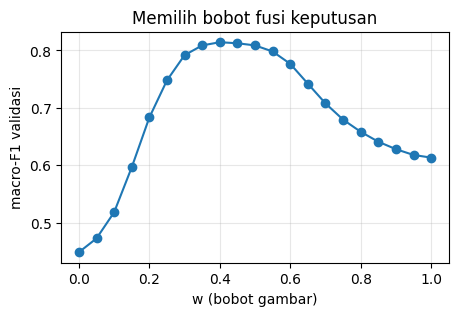

Fusi B (late fusion): macro-F1 0.8143 | lini A 0.8516 | lini B 0.6953
Fusi B (late fusion) | sensor hilang: macro-F1 0.6131 | lini A 0.6589 | lini B 0.4740


In [14]:
p_img = proba_single(m_img, X_img, y, va_idx, device)
p_sen = proba_single(m_sen, X_sen, y, va_idx, device)

grid = np.linspace(0, 1, 21)
skor = [f1_score(yv, (w * p_img + (1 - w) * p_sen).argmax(1), average='macro') for w in grid]
w_best = float(grid[int(np.argmax(skor))])
print("w terbaik (bobot gambar):", w_best)

plt.figure(figsize=(5, 3)); plt.plot(grid, skor, marker='o')
plt.xlabel('w (bobot gambar)'); plt.ylabel('macro-F1 validasi'); plt.title('Memilih bobot fusi keputusan')
plt.grid(alpha=.3); plt.show()

N_B = 'Fusi B (late fusion)'
ringkas(N_B, yv, (w_best * p_img + (1 - w_best) * p_sen).argmax(1), lini_va)
# Jika sensor hilang, fusi B kembali ke model gambar saja (w = 1)
ringkas(N_B + ' | sensor hilang', yv, p_img.argmax(1), lini_va)

## 4. Ketika data sensor tidak terekam

Sekitar 4,9% unit pada data latih tidak memiliki data sensor sama sekali (seluruh nilai NaN). Proporsi NaN pada data uji serupa: 8,1% unit memiliki NaN, dibanding 8,0% pada data latih. Karena itu model harus tetap memberi prediksi yang wajar tanpa sensor.

Tabel berikut membandingkan semua model pada data validasi yang sama. Baris yang berakhiran `| sensor hilang` adalah model yang sama yang diuji dengan sensor dikosongkan.

In [15]:
# Ringkasan semua model pada data validasi yang sama
# Baris berakhiran '| sensor hilang' = model yang sama, diuji dengan sensor dikosongkan
ringkasan = pd.DataFrame(HASIL).T[['total', 'A', 'B']].astype(float).round(4)
ringkasan.columns = ['macro-F1', 'lini A', 'lini B']
display(ringkasan)

,macro-F1,lini A,lini B
Gambar saja,0.6131,0.6589,0.4740
Sensor saja,0.4482,0.4599,0.4129
Fusi A0 (tanpa dropout),0.8214,0.8621,0.6997
Fusi A0 (tanpa dropout) | sensor hilang,0.5644,0.6130,0.4243
"Fusi A1 (dropout 0,3)",0.8325,0.8682,0.7259
"Fusi A1 (dropout 0,3) | sensor hilang",0.6078,0.6530,0.4697
Fusi B (late fusion),0.8143,0.8516,0.6953
Fusi B (late fusion) | sensor hilang,0.6131,0.6589,0.4740


Dua perbandingan yang relevan: (1) `Fusi A0 | sensor hilang` terhadap `Gambar saja`, untuk melihat apakah model yang tidak dilatih dengan dropout menurun di bawah model gambar saja; dan (2) `Fusi A1 | sensor hilang` terhadap `Fusi A0 | sensor hilang`, untuk melihat pengaruh *modality dropout*. Pada fusi B, ketiadaan sensor ditangani dengan `w = 1`, sehingga hasilnya sama dengan model gambar saja.

## 5. Perbandingan per kelas

Grafik dan tabel berikut menunjukkan F1 setiap kelas pada data validasi. Ini menjadi bukti untuk butir (c): kelas yang memperoleh manfaat dari sensor dan kelas yang memperoleh manfaat dari gambar.

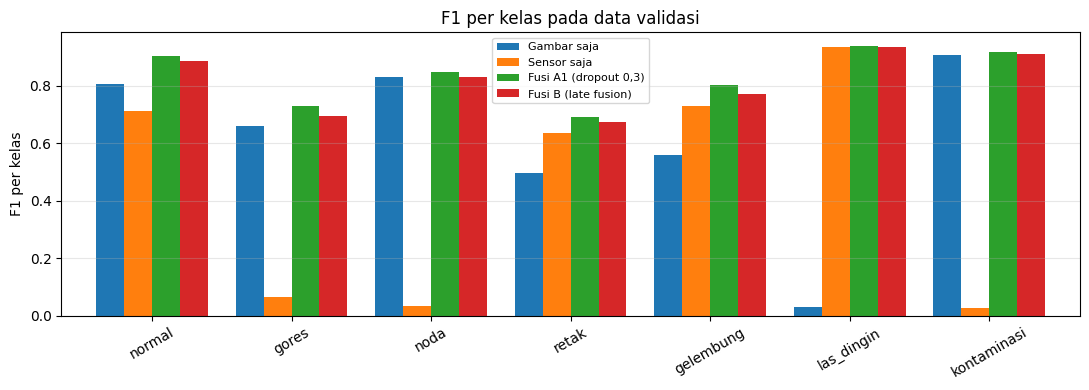

,Gambar saja,Sensor saja,"Fusi A1 (dropout 0,3)",Fusi B (late fusion)
normal,0.806,0.712,0.902,0.886
gores,0.661,0.065,0.730,0.696
noda,0.831,0.034,0.847,0.831
retak,0.496,0.636,0.690,0.673
gelembung,0.560,0.729,0.802,0.772
las_dingin,0.031,0.936,0.939,0.933
kontaminasi,0.906,0.025,0.917,0.909


In [16]:
nama_plot = [N_IMG, N_SEN, N_A1, N_B]
df = pd.DataFrame({n: HASIL[n]['per_kelas'] for n in nama_plot}).loc[KELAS]
df.plot(kind='bar', figsize=(11, 4), width=0.8)
plt.ylabel('F1 per kelas'); plt.title('F1 per kelas pada data validasi'); plt.xticks(rotation=30)
plt.legend(fontsize=8); plt.grid(axis='y', alpha=.3); plt.tight_layout(); plt.show()
display(df.round(3))

## 6. Kesimpulan

Kesimpulan di bawah disusun otomatis dari hasil eksperimen di atas, sehingga seluruh angka konsisten dengan tabel dan grafik.

In [17]:
from IPython.display import Markdown, display

def _f(x): return f"{x:.3f}".replace('.', ',')
def _d(x): return ('+' if x >= 0 else '\u2212') + f"{abs(x):.3f}".replace('.', ',')

def buat_kesimpulan(H):
    uni, fus = [N_IMG, N_SEN], [N_A0, N_A1, N_B]
    semua = uni + fus
    terbaik = max(semua, key=lambda n: H[n]['total'])
    fus_t = max(fus, key=lambda n: H[n]['total'])
    teks = []

    # 1. Perbandingan keseluruhan
    daftar = "; ".join(f"{n} {_f(H[n]['total'])}" for n in semua)
    teks.append(
        f"**1. Perbandingan keseluruhan.** Macro-F1 pada data validasi: {daftar}. "
        f"Macro-F1 tertinggi dicapai oleh **{terbaik}** ({_f(H[terbaik]['total'])}), dengan selisih "
        f"{_d(H[terbaik]['total'] - H[N_IMG]['total'])} terhadap model gambar saja dan "
        f"{_d(H[terbaik]['total'] - H[N_SEN]['total'])} terhadap model sensor saja.")

    # 2. Kontribusi per kelas
    modal = ", ".join(
        f"`{k}` ({'sensor' if H[N_SEN]['per_kelas'][k] > H[N_IMG]['per_kelas'][k] else 'gambar'})" for k in KELAS)
    selisih = sorted(
        [(k, H[fus_t]['per_kelas'][k] - max(H[N_IMG]['per_kelas'][k], H[N_SEN]['per_kelas'][k])) for k in KELAS],
        key=lambda x: -x[1])
    naik = [f"`{k}` ({_d(d)})" for k, d in selisih if d >= 0.02]
    turun = [f"`{k}` ({_d(d)})" for k, d in selisih if d <= -0.02]
    kal = (f"**2. Kontribusi modalitas per kelas.** Modalitas tunggal dengan F1 lebih tinggi pada tiap kelas: {modal}. "
           f"Dibandingkan modalitas tunggal terbaik pada kelas yang sama, model fusi dengan macro-F1 tertinggi ({fus_t}) ")
    kal += ("menaikkan F1 sebesar 0,02 atau lebih pada: " + ", ".join(naik) + ". ") if naik else "tidak menaikkan F1 sebesar 0,02 atau lebih pada kelas mana pun. "
    kal += ("Penurunan sebesar 0,02 atau lebih terjadi pada: " + ", ".join(turun) + ".") if turun else "Tidak ada kelas yang turun 0,02 atau lebih."
    teks.append(kal)

    # 3. Lini produksi
    g = lambda n: H[n]['A'] - H[n]['B']
    arah = "menyempitkan" if g(fus_t) < g(N_IMG) else "tidak menyempitkan"
    teks.append(
        f"**3. Lini produksi.** Selisih macro-F1 antara lini A dan lini B: gambar saja {_f(g(N_IMG))}, sensor saja {_f(g(N_SEN))}, "
        f"{fus_t} {_f(g(fus_t))}. Fusi {arah} selisih tersebut dibandingkan model gambar saja. "
        f"Macro-F1 lini B: gambar saja {_f(H[N_IMG]['B'])}, {fus_t} {_f(H[fus_t]['B'])}.")

    # 4. Sensor tidak terekam
    h0, h1 = H[N_A0 + ' | sensor hilang']['total'], H[N_A1 + ' | sensor hilang']['total']
    gm = H[N_IMG]['total']
    ket = "meningkatkan" if h1 > h0 else "tidak meningkatkan"
    teks.append(
        f"**4. Sensor tidak terekam.** Tanpa sensor, macro-F1 Fusi A0 adalah {_f(h0)} ({_d(h0 - gm)} terhadap gambar saja) dan "
        f"Fusi A1 adalah {_f(h1)} ({_d(h1 - gm)} terhadap gambar saja). *Modality dropout* {ket} macro-F1 tanpa sensor "
        f"sebesar {_d(h1 - h0)} dibandingkan model tanpa dropout. Fusi B memakai `w = 1` bila sensor tidak ada, "
        f"sehingga hasilnya sama dengan model gambar saja ({_f(gm)}).")

    # 5. Keterbatasan
    teks.append(
        "**5. Keterbatasan.** Hasil berasal dari satu seed dan satu pembagian validasi. Bobot fusi B disetel pada data "
        "validasi yang sama (satu parameter). Model final akan dievaluasi dengan tiga seed (butir g), dan pengaruh lini "
        "produksi akan dianalisis lebih lanjut pada butir (e).")
    return "\n\n".join(teks)

display(Markdown(buat_kesimpulan(HASIL)))

**1. Perbandingan keseluruhan.** Macro-F1 pada data validasi: Gambar saja 0,613; Sensor saja 0,448; Fusi A0 (tanpa dropout) 0,821; Fusi A1 (dropout 0,3) 0,832; Fusi B (late fusion) 0,814. Macro-F1 tertinggi dicapai oleh **Fusi A1 (dropout 0,3)** (0,832), dengan selisih +0,219 terhadap model gambar saja dan +0,384 terhadap model sensor saja.

**2. Kontribusi modalitas per kelas.** Modalitas tunggal dengan F1 lebih tinggi pada tiap kelas: `normal` (gambar), `gores` (gambar), `noda` (gambar), `retak` (sensor), `gelembung` (sensor), `las_dingin` (sensor), `kontaminasi` (gambar). Dibandingkan modalitas tunggal terbaik pada kelas yang sama, model fusi dengan macro-F1 tertinggi (Fusi A1 (dropout 0,3)) menaikkan F1 sebesar 0,02 atau lebih pada: `normal` (+0,096), `gelembung` (+0,074), `gores` (+0,069), `retak` (+0,054). Tidak ada kelas yang turun 0,02 atau lebih.

**3. Lini produksi.** Selisih macro-F1 antara lini A dan lini B: gambar saja 0,185, sensor saja 0,047, Fusi A1 (dropout 0,3) 0,142. Fusi menyempitkan selisih tersebut dibandingkan model gambar saja. Macro-F1 lini B: gambar saja 0,474, Fusi A1 (dropout 0,3) 0,726.

**4. Sensor tidak terekam.** Tanpa sensor, macro-F1 Fusi A0 adalah 0,564 (−0,049 terhadap gambar saja) dan Fusi A1 adalah 0,608 (−0,005 terhadap gambar saja). *Modality dropout* meningkatkan macro-F1 tanpa sensor sebesar +0,043 dibandingkan model tanpa dropout. Fusi B memakai `w = 1` bila sensor tidak ada, sehingga hasilnya sama dengan model gambar saja (0,613).

**5. Keterbatasan.** Hasil berasal dari satu seed dan satu pembagian validasi. Bobot fusi B disetel pada data validasi yang sama (satu parameter). Model final akan dievaluasi dengan tiga seed (butir g), dan pengaruh lini produksi akan dianalisis lebih lanjut pada butir (e).

## 7. Penyimpanan hasil

Hasil eksperimen (macro-F1 total, per lini, dan per kelas) disimpan dalam berkas JSON di repositori sebagai bahan laporan. Kode di-commit ke repositori kelompok melalui branch `task1-fusi`. Bobot model tidak disertakan dalam commit.

In [18]:
import json, os
os.makedirs('/content/UTSDEEPLEARNING/kode/task1_klasifikasi/hasil', exist_ok=True)
with open('/content/UTSDEEPLEARNING/kode/task1_klasifikasi/hasil/fusi_seed0.json', 'w') as f:
    json.dump({'seed': SEED, 'epochs': EPOCHS, 'w_fusi_B': w_best, 'hasil': HASIL}, f, indent=2)
print(open('/content/UTSDEEPLEARNING/kode/task1_klasifikasi/hasil/fusi_seed0.json').read()[:600])

{
  "seed": 0,
  "epochs": 15,
  "w_fusi_B": 0.4,
  "hasil": {
    "Gambar saja": {
      "total": 0.6131355518793915,
      "A": 0.6589065796922194,
      "B": 0.47397887389936155,
      "per_kelas": {
        "normal": 0.8064754856614246,
        "gores": 0.661373190098085,
        "noda": 0.8307193077339102,
        "retak": 0.4958427815570673,
        "gelembung": 0.5604670558798999,
        "las_dingin": 0.030612244897959183,
        "kontaminasi": 0.9064587973273942
      }
    },
    "Sensor saja": {
      "total": 0.4481856142471824,
      "A": 0.4599490065189614,
      "B": 0.41288057


In [19]:
%cd /content/UTSDEEPLEARNING
!git add kode/task1_klasifikasi/*.py kode/task1_klasifikasi/hasil/*.json
!git commit -m "Task 1: fusi gambar+sensor (fitur dan keputusan), modality dropout"
!git push origin task1-fusi

/content/UTSDEEPLEARNING
[task1-fusi 3a03e5c] Task 1: fusi gambar+sensor (fitur dan keputusan), modality dropout
 1 file changed, 78 insertions(+), 78 deletions(-)
Enumerating objects: 11, done.
Counting objects: 100% (11/11), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (6/6), 1.47 KiB | 1.47 MiB/s, done.
Total 6 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/rafiptrnto/UTSDEEPLEARNING.git
   957a6f2..3a03e5c  task1-fusi -> task1-fusi
